# Lab 2 - What Did the Campaign Deliver?
Name: Полєжаєв Єгор Олексійович | Polezhayev Yehor Oleksiyovych | Group: КМ-41


## Setup


In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

for df in [programs, viewings, commercials]:
    df["start_ts"] = pd.to_datetime(df["start_ts"])
for df in [programs, viewings]:
    df["end_ts"] = pd.to_datetime(df["end_ts"])
for df in [programs, daily_weights]:
    df["broadcast_date"] = pd.to_datetime(df["broadcast_date"]).dt.date

P = daily_weights[daily_weights.resp_type.isin(["R", "L"])].copy()
p_sess = viewings[viewings.resp_type.isin(["R", "L"])].copy()

age = viewer_attributes[viewer_attributes.attr_id == 300][["respondent_id", "value"]].rename(columns={"value": "age"})
age["age"] = pd.to_numeric(age["age"], errors="coerce")
a1849_ids = set(age[(age.age >= 18) & (age.age <= 49)].respondent_id)

p_month = P.groupby("respondent_id")["weight"].mean().rename("monthly_weight").reset_index()
univ_p2 = p_month.monthly_weight.sum()
univ_a = p_month[p_month.respondent_id.isin(a1849_ids)].monthly_weight.sum()

BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]
SMALL = ["FX", "BRAVO", "HGTV", "FOOD", "HIST"]


## Task 1.1 - Size


In [2]:
print("Spots:", len(commercials))
print("Pods:", commercials.pod_id.nunique())
print("Brands:", commercials.brand.nunique())
print("Categories:", commercials.category.nunique())

ba = commercials[commercials.brand == "BRAND_A"]
print("BRAND_A spots:", len(ba))
print(ba.network_code.value_counts().sort_index())


Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300
network_code
ABC      29
BRAVO    33
CBS      22
FNC      40
FOOD     33
FOX      13
FX       38
HGTV     39
HIST     37
NBC      16
Name: count, dtype: int64


## Task 1.2 - Ad load


In [3]:
c = commercials.copy()
c["ad_min"] = c.length_sec / 60
c["hour_floor"] = c.start_ts.dt.floor("h")

tot = c.groupby("network_code")["ad_min"].sum()
hrs = c.groupby(["network_code", "hour_floor"]).size().groupby("network_code").size()
avg = (tot / hrs).round(2)

load = pd.DataFrame({"total_min": tot.round(1), "hours_with_ads": hrs, "avg_min_per_hour": avg})
print(load.sort_values("avg_min_per_hour", ascending=False))
print("Heaviest ad load:", load.avg_min_per_hour.idxmax())


              total_min  hours_with_ads  avg_min_per_hour
network_code                                             
FNC             11619.5             743             15.64
BRAVO            8369.5             623             13.43
HGTV             8286.5             621             13.34
HIST             8214.0             622             13.21
FOOD             8130.5             620             13.11
FX               8020.5             621             12.92
CBS              5182.2             427             12.14
ABC              4133.2             349             11.84
NBC              3535.0             299             11.82
FOX              2310.0             196             11.79
Heaviest ad load: FNC


**Answer:** Broadcast networks (CBS, NBC, ABC, FOX) have whole hours without national ads because those breaks are sold locally by stations. Cable networks sell the full day nationally, so their ad load is more continuous. FNC has the heaviest load.


## Task 1.3 - Price everything


In [4]:
# attach program_name
spots = commercials.merge(programs[["telecast_id", "program_name"]], on="telecast_id", how="left")

# program rows from rate card
prog_rc = rate_card[rate_card.program_name.notna()][["network_code", "program_name", "cost_30s_usd", "daypart"]].drop_duplicates()
spots = spots.merge(prog_rc, on=["network_code", "program_name"], how="left")

def broadcast_mins_wd(ts):
    hour, minute = ts.hour, ts.minute
    if hour < 6:
        mins = (hour + 24 - 6) * 60 + minute
        wd = (ts - pd.Timedelta(days=1)).weekday()
    else:
        mins = (hour - 6) * 60 + minute
        wd = ts.weekday()
    return mins, wd

mask = spots.cost_30s_usd.isna()
spots.loc[mask, "mins"], spots.loc[mask, "wd"] = zip(*spots.loc[mask, "start_ts"].map(broadcast_mins_wd))

time_rc = rate_card[rate_card.program_name.isna()].copy()
def to_mins(t):
    h, m = map(int, t.split(":"))
    return (h - 6) * 60 + m
time_rc["start_m"] = time_rc.start_time.map(to_mins)
time_rc["end_m"] = time_rc.end_time.map(to_mins)
time_exp = time_rc.explode("weekdays").rename(columns={"weekdays": "wd"})

un = spots.loc[mask, ["ad_airing_id", "network_code", "mins", "wd"]]
matched = un.merge(time_exp[["network_code", "wd", "start_m", "end_m", "cost_30s_usd", "daypart"]],
                   on=["network_code", "wd"], how="left")
matched = matched[(matched.mins >= matched.start_m) & (matched.mins < matched.end_m)]

spots = spots.merge(matched[["ad_airing_id", "cost_30s_usd", "daypart"]], on="ad_airing_id", how="left", suffixes=("", "_t"))
spots["cost_30s"] = spots.cost_30s_usd.fillna(spots.cost_30s_usd_t)
spots["daypart_final"] = spots.daypart.fillna(spots.daypart_t)
spots["from_program"] = spots.cost_30s_usd.notna()
spots["cost"] = spots.cost_30s * (spots.length_sec / 30)

print("Spots without a price:", spots.cost.isna().sum())

tot = spots.groupby("network_code")["cost"].sum()
prog_val = spots[spots.from_program].groupby("network_code")["cost"].sum()
share = (prog_val / tot).fillna(0)
print(pd.DataFrame({"value_M": (tot / 1e6).round(2), "share_from_program": share.round(3)}))


Spots without a price: 0
              value_M  share_from_program
network_code                             
ABC            708.79               0.432
BRAVO           25.31               0.000
CBS            818.78               0.230
FNC            315.85               0.000
FOOD            42.15               0.000
FOX            696.17               0.835
FX              42.51               0.000
HGTV            58.10               0.000
HIST            40.09               0.000
NBC            724.32               0.342


## Task 2.1 - Delivery


In [5]:
ba = spots[spots.brand == "BRAND_A"][["ad_airing_id", "network_code", "start_ts", "cost"]].copy()

# who saw each spot
exposures = []
for net in ba.network_code.unique():
    net_spots = ba[ba.network_code == net]
    sess = p_sess[p_sess.network_code == net]
    for _, s in net_spots.iterrows():
        cover = sess[(sess.start_ts <= s.start_ts) & (sess.end_ts > s.start_ts)]
        if len(cover):
            exp = cover[["respondent_id", "weight"]].copy()
            exp["ad_airing_id"] = s.ad_airing_id
            exposures.append(exp)
exp_df = pd.concat(exposures, ignore_index=True)

# broadcast date for spots
def bdate(ts):
    if ts.hour < 6:
        return (ts - pd.Timedelta(days=1)).date()
    return ts.date()
ba["broadcast_date"] = ba.start_ts.map(bdate)

# daily universe
P2 = daily_weights[daily_weights.resp_type.isin(["R", "L"])].copy()
P2["broadcast_date"] = pd.to_datetime(P2["broadcast_date"]).dt.date
P2 = P2.merge(age[["respondent_id", "age"]], on="respondent_id", how="left")
P2["is_a"] = P2.respondent_id.isin(a1849_ids)

day_univ = P2.groupby("broadcast_date").agg(
    univ_p2=("weight", "sum"),
    univ_a=("weight", lambda x: x[P2.loc[x.index, "is_a"]].sum())
).reset_index()

# impressions and ratings
imp = exp_df.groupby("ad_airing_id")["weight"].sum().rename("imp_p2").reset_index()
imp_a = exp_df[exp_df.respondent_id.isin(a1849_ids)].groupby("ad_airing_id")["weight"].sum().rename("imp_a").reset_index()
ba = ba.merge(imp, on="ad_airing_id", how="left").merge(imp_a, on="ad_airing_id", how="left")
ba["imp_p2"] = ba.imp_p2.fillna(0)
ba["imp_a"] = ba.imp_a.fillna(0)
ba = ba.merge(day_univ, on="broadcast_date", how="left")
ba["rating_p2"] = ba.imp_p2 / ba.univ_p2 * 100
ba["rating_a"] = ba.imp_a / ba.univ_a * 100

grps_p2 = ba.rating_p2.sum()
grps_a = ba.rating_a.sum()
imp_p2_m = ba.imp_p2.sum() / 1e6
imp_a_m = ba.imp_a.sum() / 1e6

# reach
reached = exp_df.drop_duplicates("respondent_id").merge(p_month, on="respondent_id")
reach_p2 = reached.monthly_weight.sum() / univ_p2 * 100
reach_a = reached[reached.respondent_id.isin(a1849_ids)].monthly_weight.sum() / univ_a * 100
freq_p2 = grps_p2 / reach_p2
freq_a = grps_a / reach_a

print("P2+ impressions (M):", round(imp_p2_m, 1))
print("P2+ GRPs:", round(grps_p2, 1))
print("P2+ reach (%):", round(reach_p2, 1))
print("P2+ average frequency:", round(freq_p2, 2))
print("A18-49 impressions (M):", round(imp_a_m, 1))
print("A18-49 GRPs:", round(grps_a, 1))
print("A18-49 reach (%):", round(reach_a, 1))
print("A18-49 average frequency:", round(freq_a, 2))


P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.03
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 1.98


## Task 2.2 - Frequency distribution


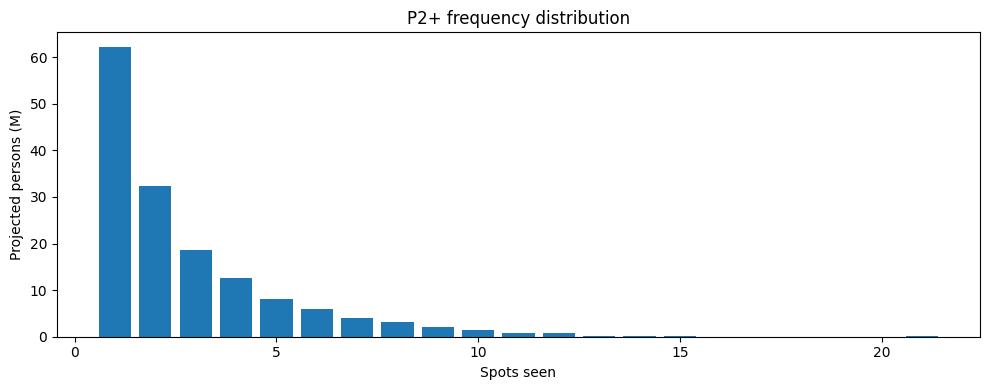

Share of impressions at 5+ exposures: 0.444


In [6]:
freq = exp_df.groupby("respondent_id").agg(
    n_spots=("ad_airing_id", "nunique"),
    imp=("weight", "sum")
).reset_index()
freq = freq.merge(p_month, on="respondent_id")

dist = freq.groupby("n_spots")["monthly_weight"].sum() / 1e6
plt.figure(figsize=(10, 4))
plt.bar(dist.index, dist.values)
plt.xlabel("Spots seen")
plt.ylabel("Projected persons (M)")
plt.title("P2+ frequency distribution")
plt.tight_layout()
plt.show()

share5 = freq[freq.n_spots >= 5]["imp"].sum() / freq["imp"].sum()
print("Share of impressions at 5+ exposures:", round(share5, 3))


**Answer:** Average frequency is only a rough summary. Many people saw just 1 or 2 spots, while a smaller group saw 5 or more and absorbed a large share of the impressions. The mean is pulled up by the heavy viewers.


## Task 2.3 - On target?


In [7]:
share_a = ba.imp_a.sum() / ba.imp_p2.sum()
print("Share of impressions on A18-49:", round(share_a, 3))

# by network
net_imp = ba.groupby("network_code").agg(imp_p2=("imp_p2", "sum"), imp_a=("imp_a", "sum"))
net_imp["share_a"] = net_imp.imp_a / net_imp.imp_p2
print(net_imp[["share_a"]].sort_values("share_a", ascending=False).round(3))


Share of impressions on A18-49: 0.194
              share_a
network_code         
FX              0.651
BRAVO           0.554
FOOD            0.316
HGTV            0.306
FOX             0.242
HIST            0.202
NBC             0.189
ABC             0.180
CBS             0.154
FNC             0.047


**Answer:** The target is about 42% of persons. Only 19.4% of campaign impressions landed on A18-49, so the plan under-delivered.
FX and BRAVO over-indexed on the target (65% and 55%); the big broadcast networks and especially FNC (only 5%) pulled the mix older.


## Task 3.1 - Cost


In [8]:
camp_cost = ba.cost.sum()
cpm_p2 = camp_cost / (ba.imp_p2.sum() / 1000)
cpp_p2 = camp_cost / grps_p2
cpm_a = camp_cost / (ba.imp_a.sum() / 1000)
cpp_a = camp_cost / grps_a

print("Campaign cost (USD):", int(camp_cost))
print("P2+ CPM (USD):", round(cpm_p2, 2))
print("P2+ CPP (USD):", round(cpp_p2, 0))
print("A18-49 CPM (USD):", round(cpm_a, 2))
print("A18-49 CPP (USD):", round(cpp_a, 0))


Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221.0
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836.0


## Task 3.2 - By network


In [9]:
by_net = ba.groupby("network_code").agg(
    spots=("ad_airing_id", "count"),
    cost=("cost", "sum"),
    imp_p2=("imp_p2", "sum"),
    imp_a=("imp_a", "sum")
)
by_net["cpm_p2"] = by_net.cost / (by_net.imp_p2 / 1000)
by_net["cpm_a"] = by_net.cost / (by_net.imp_a / 1000)
print(by_net.round(2).sort_values("cost", ascending=False))


              spots       cost      imp_p2       imp_a  cpm_p2   cpm_a
network_code                                                          
FOX              13  2434700.0  76255700.0  18440098.0   31.93  132.03
ABC              29  1625700.0  94211430.0  16988998.0   17.26   95.69
CBS              22  1488700.0  88980316.0  13693421.0   16.73  108.72
NBC              16   796800.0  41435020.0   7833538.0   19.23  101.72
FNC              40   526300.0  57798176.0   2717037.0    9.11  193.70
HGTV             39   230000.0  24657356.0   7554439.0    9.33   30.45
FOOD             33    96620.0   9481466.0   2991886.0   10.19   32.29
FX               38    92200.0   8522567.0   5551130.0   10.82   16.61
HIST             37    79640.0  12329303.0   2484757.0    6.46   32.05
BRAVO            33    49610.0   5084258.0   2817365.0    9.76   17.61


**Answer:** Most of the money went to FOX, ABC and CBS. The cheapest networks for A18-49 were FX and BRAVO (CPM around 17), then HGTV, FOOD and HIST (around 30). FNC was cheap on P2+ but very expensive on the target.


## Task 3.3 - Guarantee


In [10]:
guarantee = 150
met = grps_p2 >= guarantee
owed = max(0, guarantee - grps_p2)
value_owed = owed * cpp_p2
print("Guarantee met:", met)
print("Make-good GRPs owed:", round(owed, 1))
print("Value of make-goods (USD):", int(round(value_owed)))


Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012882


## Task 4 - Do networks add up?


In [11]:
ba["group"] = ba.network_code.apply(lambda x: "big" if x in BIG else "small")

def reach_for(ids):
    r = exp_df[exp_df.ad_airing_id.isin(ids)].drop_duplicates("respondent_id")
    r = r.merge(p_month, on="respondent_id")
    return r.monthly_weight.sum() / univ_p2 * 100

reach_big = reach_for(ba[ba.group == "big"].ad_airing_id)
reach_small = reach_for(ba[ba.group == "small"].ad_airing_id)
reach_all = reach_p2
overlap = reach_big + reach_small - reach_all
overlap_pct = overlap  # already in points of reach
# share of P2+ that is in both
# people in both
big_ids = set(exp_df[exp_df.ad_airing_id.isin(ba[ba.group=="big"].ad_airing_id)].respondent_id)
small_ids = set(exp_df[exp_df.ad_airing_id.isin(ba[ba.group=="small"].ad_airing_id)].respondent_id)
both = big_ids & small_ids
both_w = p_month[p_month.respondent_id.isin(both)].monthly_weight.sum()
overlap_share = both_w / univ_p2 * 100
# expected if independent
exp_ind = (reach_big / 100) * (reach_small / 100) * 100

added = reach_all - reach_big
cost_small = ba[ba.group == "small"].cost.sum()
cost_big = ba[ba.group == "big"].cost.sum()
cost_per_added = cost_small / added if added > 0 else np.nan
cost_per_big = cost_big / reach_big

print("Reach, big networks (%):", round(reach_big, 1))
print("Reach, small networks (%):", round(reach_small, 1))
print("Reach, whole campaign (%):", round(reach_all, 1))
print("Overlap (%):", round(overlap_share, 1))
print("Overlap if independent (%):", round(exp_ind, 1))
print("Reach added by small networks (points):", round(added, 1))
print("Cost per added reach point, small (USD):", int(round(cost_per_added)))
print("Cost per reach point, big (USD):", int(round(cost_per_big)))


Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** Reach does not add because many people watch both groups. Observed overlap (8.7%) is higher than the independent expectation (4.9%), so small-network viewers are more likely than average to already have been reached by the big networks. Each reach point added by the small networks still cost less than a reach point on the big networks, so that spend was reasonable.


## Task 5 - How sure are we?


In [12]:
# panelists per spot (unweighted R+L)
n_panel = exp_df.groupby("ad_airing_id")["respondent_id"].nunique()
ba = ba.merge(n_panel.rename("n_panel"), on="ad_airing_id", how="left")
ba["n_panel"] = ba.n_panel.fillna(0).astype(int)

print("Median panelists per spot:", int(ba.n_panel.median()))
print("Spots seen by no panelist:", (ba.n_panel == 0).sum())

# SE
# p = rating/100, n = in-tab that day (approx use average or actual)
# relative SE = SE / rating
ba["p"] = ba.rating_p2 / 100
# n = number of persons in-tab that day (P2+)
day_n = P2.groupby("broadcast_date")["respondent_id"].nunique().rename("n_intab")
ba = ba.merge(day_n, on="broadcast_date", how="left")
ba["se"] = np.sqrt(ba.p * (1 - ba.p) / ba.n_intab) * 100
ba["rel_se"] = ba.se / ba.rating_p2.replace(0, np.nan)

ba["is_big"] = ba.network_code.isin(BIG)
print("Median relative SE, big networks:", round(ba[ba.is_big].rel_se.median(), 3))
print("Median relative SE, small networks:", round(ba[~ba.is_big].rel_se.median(), 3))

# zero-cell W18-34
sex = viewer_attributes[viewer_attributes.attr_id.isin([201, 202])][["respondent_id", "attr_id"]].copy()
sex["sex"] = sex.attr_id.map({201: "M", 202: "W"})
w_ids = set(sex[sex.sex == "W"].respondent_id)
w1834 = set(age[(age.age >= 18) & (age.age <= 34)].respondent_id) & w_ids

exp_w = exp_df[exp_df.respondent_id.isin(w1834)]
spots_with_w = set(exp_w.ad_airing_id)
zero = (~ba.ad_airing_id.isin(spots_with_w)).sum()
print("W18-34 zero-cell spots:", int(zero))


Median panelists per spot: 12
Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** A zero rating means no woman aged 18-34 in the panel saw that spot. With only a few thousand panelists, many spots (especially on small networks) have zero or single-digit panelists behind them, so the rating is noisy. I would tell the client that W18-34 ratings by individual spot are not reliable; report them only at the campaign or network level.
